In [2]:
from pathlib import Path
import shutil
import subprocess

DATASET_ID = "cetaamb/reto-1-cartografa-automatizada"
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "streamlit_app.py").is_file():
    candidate = PROJECT_ROOT / "cartografia_panoptica"
    if (candidate / "streamlit_app.py").is_file():
        PROJECT_ROOT = candidate
    else:
        raise FileNotFoundError("Abre el notebook desde la carpeta del proyecto o su carpeta padre.")
BASE_DIR = PROJECT_ROOT.parent
DATASET_ARCHIVE = BASE_DIR / "reto-1-cartografa-automatizada.zip"
DATASET_DIR = BASE_DIR / "reto-1-cartografa-automatizada"

if not DATASET_ARCHIVE.is_file():
    kaggle_executable = shutil.which("kaggle")
    if kaggle_executable is None:
        raise FileNotFoundError(
            f"No se encontró {DATASET_ARCHIVE}. Instala la CLI de Kaggle (pip install kaggle) "
            "o coloca el ZIP en la carpeta de trabajo del notebook."
        )

    credentials_file = Path.home() / ".kaggle" / "kaggle.json"
    if not credentials_file.is_file():
        raise FileNotFoundError(
            f"Falta el archivo de credenciales de Kaggle: {credentials_file}. "
            "Descárgalo desde tu cuenta de Kaggle y guárdalo en esa ubicación."
        )

    subprocess.run(
        [kaggle_executable, "datasets", "download", "-d", DATASET_ID, "-p", str(BASE_DIR)],
        cwd=BASE_DIR,
        check=True,
    )

print(f"Archivo del dataset: {DATASET_ARCHIVE}")

Archivo del dataset: /home/juan/Deep Computer Vision/Taller 3Cartografia/reto-1-cartografa-automatizada.zip


In [3]:
import zipfile

zip_file_path = DATASET_ARCHIVE
extract_path = DATASET_DIR

extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_file_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print(f"Dataset descomprimido en: {extract_path}")

Dataset descomprimido en: /home/juan/Deep Computer Vision/Taller 3Cartografia/reto-1-cartografa-automatizada


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

for dirname, _, filenames in os.walk(DATASET_DIR):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/home/juan/Deep Computer Vision/Taller 3Cartografia/reto-1-cartografa-automatizada/Dataset segmentacion/ground_truth_recorte_78.npy
/home/juan/Deep Computer Vision/Taller 3Cartografia/reto-1-cartografa-automatizada/Dataset segmentacion/recorte_18.png
/home/juan/Deep Computer Vision/Taller 3Cartografia/reto-1-cartografa-automatizada/Dataset segmentacion/ground_truth_recorte_69.npy
/home/juan/Deep Computer Vision/Taller 3Cartografia/reto-1-cartografa-automatizada/Dataset segmentacion/ground_truth_recorte_98.npy
/home/juan/Deep Computer Vision/Taller 3Cartografia/reto-1-cartografa-automatizada/Dataset segmentacion/ground_truth_recorte_67.npy
/home/juan/Deep Computer Vision/Taller 3Cartografia/reto-1-cartografa-automatizada/Dataset segmentacion/ground_truth_recorte_95.npy
/home/juan/Deep Computer Vision/Taller 3Cartografia/reto-1-cartografa-automatizada/Dataset segmentacion/ground_truth_recorte_10.npy
/home/juan/Deep Computer Vision/Taller 3Cartografia/reto-1-cartografa-automatizada/Datase

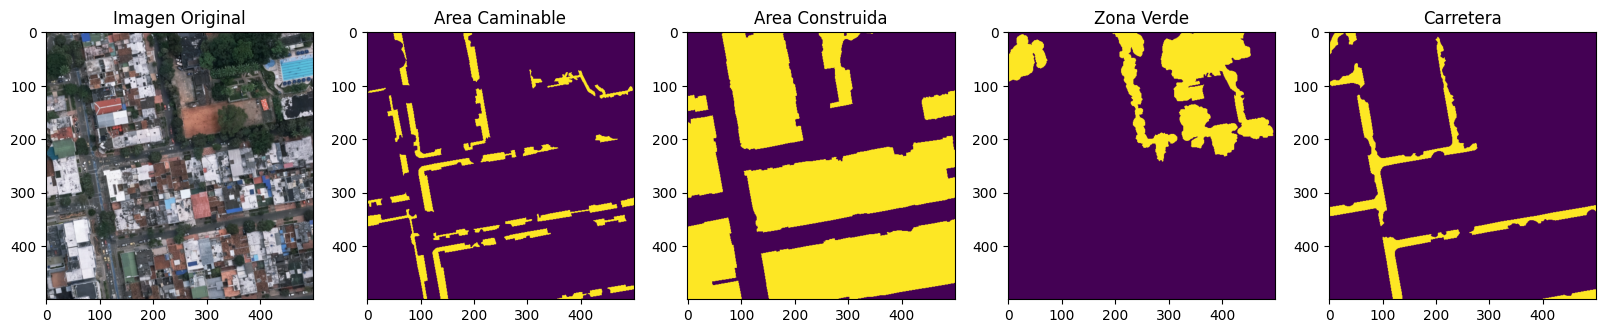

In [5]:
os.chdir(DATASET_DIR)

plt.figure(figsize = (20,25))
img_original = np.asarray(Image.open('Dataset segmentacion/recorte_64.png'))
plt.subplot(1, 5, 1)
plt.imshow(img_original)
plt.title("Imagen Original")

ground_truth = np.load('Dataset segmentacion/ground_truth_recorte_64.npy')
plt.subplot(1, 5, 2)
plt.imshow(ground_truth[:,:,0])
plt.title("Area Caminable")

ground_truth = np.load('Dataset segmentacion/ground_truth_recorte_64.npy')
plt.subplot(1, 5, 3)
plt.imshow(ground_truth[:,:,1])
plt.title("Area Construida")

ground_truth = np.load('Dataset segmentacion/ground_truth_recorte_64.npy')
plt.subplot(1, 5, 4)
plt.imshow(ground_truth[:,:,2])
plt.title("Zona Verde")

ground_truth = np.load('Dataset segmentacion/ground_truth_recorte_64.npy')
plt.subplot(1, 5, 5)
plt.imshow(ground_truth[:,:,3])
plt.title("Carretera")

plt.show()

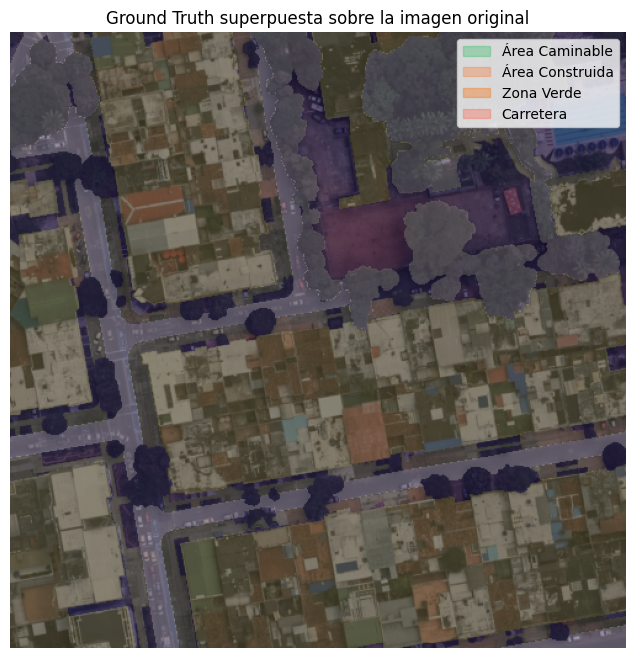

In [6]:
plt.figure(figsize=(8, 8))

img_original = np.asarray(Image.open('Dataset segmentacion/recorte_64.png'))

plt.imshow(img_original, alpha=0.9)

ground_truth = np.load('Dataset segmentacion/ground_truth_recorte_64.npy')

cmaps = ['viridis', 'plasma', 'inferno', 'magma']
for i in range(4):
    plt.imshow(ground_truth[:, :, i], cmap=cmaps[i], alpha=0.2)

labels = ["Área Caminable", "Área Construida", "Zona Verde", "Carretera"]
handles = [plt.Rectangle((0,0),1,1, color=cmap(0.7), alpha=0.4) for cmap in [plt.cm.viridis, plt.cm.plasma, plt.cm.inferno, plt.cm.magma]]
plt.legend(handles, labels, loc='upper right')

plt.title('Ground Truth superpuesta sobre la imagen original')
plt.axis('off')
plt.show()

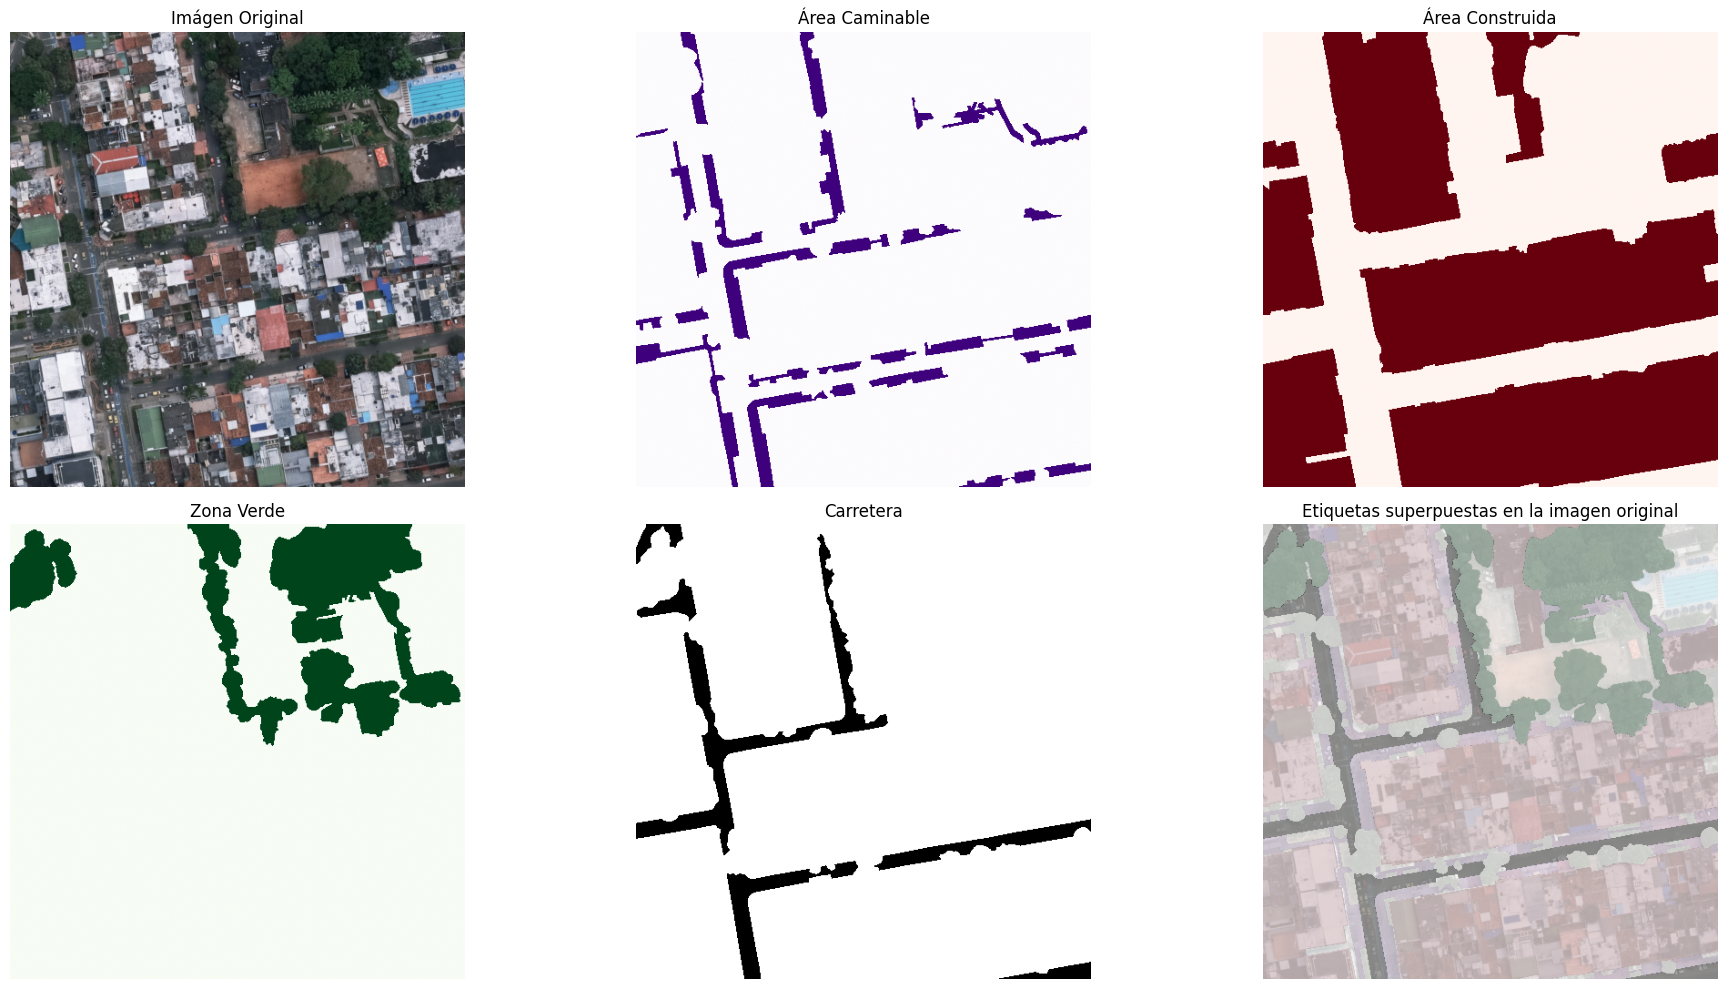

In [7]:
plt.figure(figsize=(20, 10))

img_original = np.asarray(Image.open('Dataset segmentacion/recorte_64.png'))
plt.subplot(2, 3, 1)
plt.imshow(img_original)
plt.title("Imágen Original")
plt.axis('off')

ground_truth = np.load('Dataset segmentacion/ground_truth_recorte_64.npy')

cmaps = ['Purples', 'Reds', 'Greens', 'Greys']
labels = ["Área Caminable", "Área Construida", "Zona Verde", "Carretera"]

for i in range(4):
    plt.subplot(2, 3, i + 2)
    plt.imshow(ground_truth[:, :, i], cmap=cmaps[i])
    plt.title(labels[i])
    plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(img_original, alpha=0.9)

for i in range(4):
    plt.imshow(ground_truth[:, :, i], cmap=cmaps[i], alpha=0.3)
plt.title('Etiquetas superpuestas en la imagen original')
plt.axis('off')

plt.tight_layout()
plt.show()

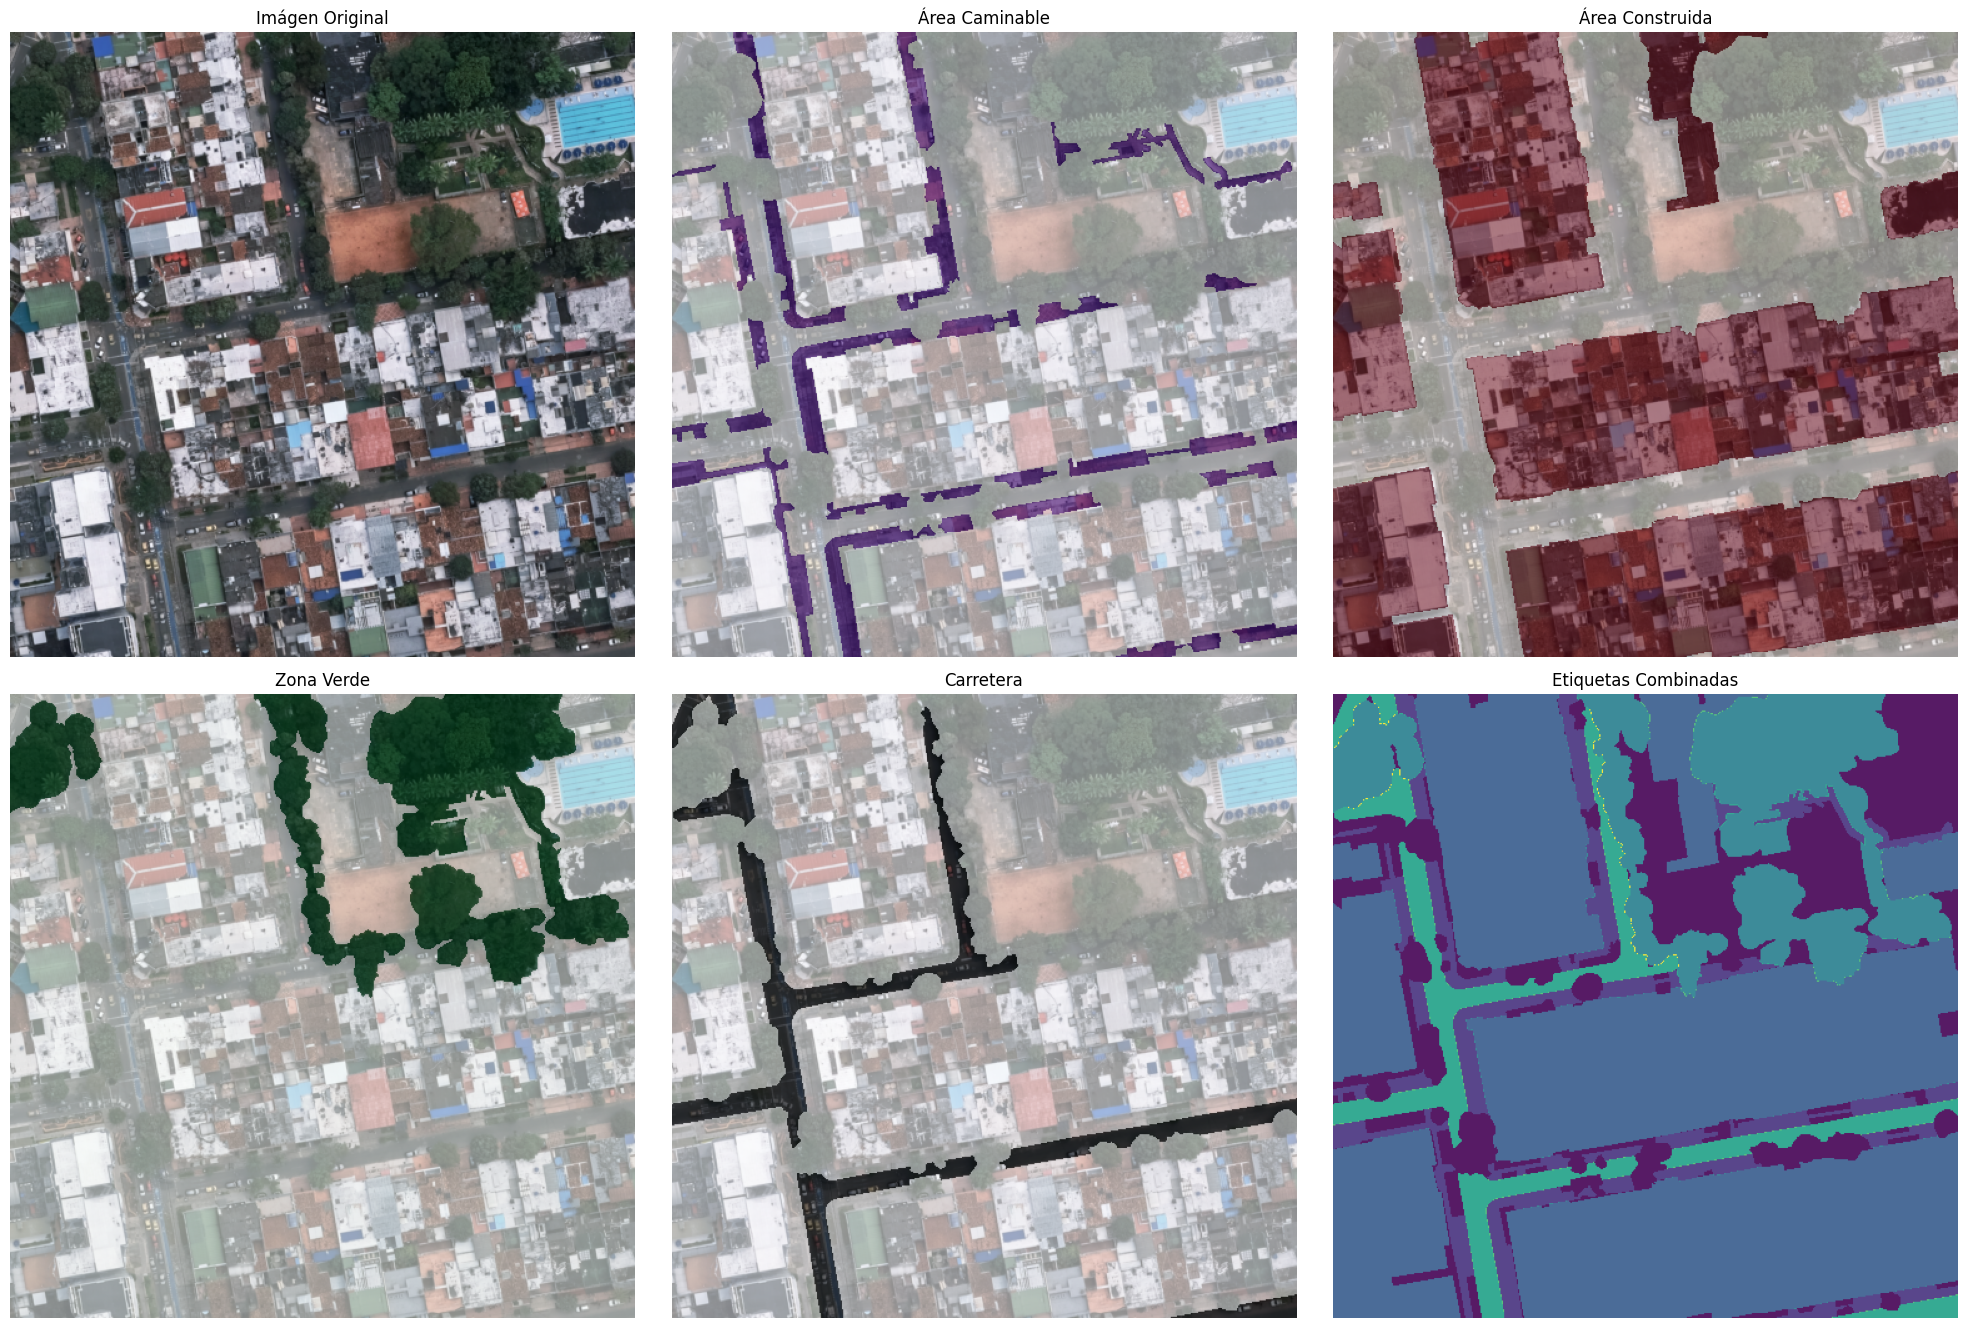

In [8]:
plt.figure(figsize=(20, 20))

img_original = np.asarray(Image.open('Dataset segmentacion/recorte_64.png'))

ground_truth = np.load('Dataset segmentacion/ground_truth_recorte_64.npy')

cmaps = ['Purples', 'Reds', 'Greens', 'Greys']
labels = ["Área Caminable", "Área Construida", "Zona Verde", "Carretera"]

plt.subplot(3, 3, 1)
plt.imshow(img_original)
plt.title("Imágen Original")
plt.axis('off')

for i in range(4):
    plt.subplot(3, 3, i + 2)
    plt.imshow(img_original)
    plt.imshow(ground_truth[:, :, i], cmap=cmaps[i], alpha=0.5)
    plt.title(labels[i])
    plt.axis('off')

combined_overlay = np.zeros_like(ground_truth[:, :, 0], dtype=np.float32)
for i in range(4):
    combined_overlay += ground_truth[:, :, i] * (i + 1)

plt.subplot(3, 3, 6)
plt.imshow(combined_overlay, cmap='viridis', alpha=0.9)
plt.title("Etiquetas Combinadas")
plt.axis('off')

plt.tight_layout()
plt.show()